# 05 — Clustering Analysis (corrected, reproducible)

This notebook uses the standardized account-level data exported in Part 4 to explore clustering. Run cells **in order** using **Restart → Run All** after confirming the Part 4 export exists.

**Important data-quality rule:** any missing or infinite numeric values are reported and temporarily filled with each feature's median in Section A so the experiment can run. If any values are repaired, investigate and correct the source feature transformation in Part 4 before treating the findings as final.

We test K-means for K=2–8, compare four feature configurations, examine a K=4 **illustrative baseline**, visualize profiles with PCA, and compare account groups. Scores and cluster descriptions must be determined from the newly executed results, not older notebook output.

In [1]:
# PART 5 — Robust setup: run this cell first
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

RANDOM_STATE = 42
K_VALUES = range(2, 9)
K_BASELINE = 4  # Comparison baseline, not automatically the optimal K

# Find the project folder from the notebook's working directory.
# This works when Jupyter starts in the project root or its notebooks folder.
current = Path.cwd().resolve()
search_roots = [current, *current.parents]
PROJECT_ROOT = next(
    (root for root in search_roots
     if (root / 'data' / 'data_processed' / 'df_clustering_features.csv.gz').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        'Cannot locate data/data_processed/df_clustering_features.csv.gz. '
        'Run the final export in Part 4 and check your project directory.'
    )

PROCESSED_DIR = PROJECT_ROOT / 'data' / 'data_processed'
DATA_PATH = PROCESSED_DIR / 'df_clustering_features.csv.gz'
OUTPUT_DIR = PROJECT_ROOT / 'data' / 'clustering_results'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
account_keys = ['ioCountry', 'accountid']

df_clustering = pd.read_csv(
    DATA_PATH,
    dtype={'ioCountry': 'string', 'accountid': 'string'},
)
missing_ids = [c for c in account_keys if c not in df_clustering.columns]
if missing_ids:
    raise ValueError(f'Missing account identifier columns: {missing_ids}')
if df_clustering.duplicated(account_keys).any():
    raise ValueError('Duplicate account identifiers: verify the Part 4 export before clustering.')

features_all = df_clustering.select_dtypes(include=np.number).columns.tolist()
if not features_all:
    raise ValueError('No numerical clustering features found in the exported file.')

# Audit + repair invalid numeric values before running any clustering algorithm.
# The exported dataset SHOULD be clean already. Any nonfinite values are reported.
feature_data = df_clustering[features_all].replace([np.inf, -np.inf], np.nan).copy()
missing_before = feature_data.isna().sum().sort_values(ascending=False)
bad = missing_before[missing_before > 0]
print('PROJECT:', PROJECT_ROOT)
print('INPUT:', DATA_PATH)
print('Accounts:', len(df_clustering), '| Numerical features:', len(features_all))
print('Nonfinite values by feature BEFORE repair:')
print(bad.to_string() if not bad.empty else 'None')
print('Total invalid entries:', int(missing_before.sum()))

# Safeguard to avoid fitting on wholly absent columns.
empty_cols = feature_data.columns[feature_data.isna().all()].tolist()
if empty_cols:
    raise ValueError(f'Entirely empty numeric features: {empty_cols}. Fix these in Part 4.')

# Temporary downstream repair: median of each already-scaled column.
# Repair the source Part 4 transformation later if any values were reported.
if not bad.empty:
    medians = feature_data.median()
    feature_data = feature_data.fillna(medians)
    print('WARNING: nonfinite values filled by per-feature median for this experiment.')
    missing_before.rename('nonfinite_count').to_csv(OUTPUT_DIR / 'input_quality_audit.csv')

if not np.isfinite(feature_data.to_numpy(dtype=np.float64)).all():
    raise ValueError('Numerical data still contains NaN or infinity after repair.')

# Keep cleaned values in the dataframe used by ALL later sections.
df_clustering.loc[:, features_all] = feature_data
account_ids = df_clustering[account_keys].copy()
print('Remaining invalid numeric values:', int(df_clustering[features_all].isna().sum().sum()))
print('Features:', features_all)

PROJECT: /Users/ramy/Courses/Data Mining /project/Data-Mining-Project-
INPUT: /Users/ramy/Courses/Data Mining /project/Data-Mining-Project-/data/data_processed/df_clustering_features.csv.gz
Accounts: 86525 | Numerical features: 15
Nonfinite values by feature BEFORE repair:
repost_ratio       1
reply_ratio        1
mention_ratio      1
hashtag_ratio      1
url_ratio          1
avg_post_length    1
Total invalid entries: 6
Remaining invalid numeric values: 0
Features: ['post_count', 'ambiguous_post_count', 'posting_intensity', 'follower_count', 'following_count', 'account_age_days', 'activity_lifespan_days', 'repost_ratio', 'reply_ratio', 'mention_ratio', 'hashtag_ratio', 'url_ratio', 'avg_post_length', 'unique_languages', 'unique_applications']


In [2]:
# Four candidate feature sets, created from the SAME validated input
candidate_feature_sets = {
    'all_features': features_all,
    'no_intensity': [c for c in features_all if c != 'posting_intensity'],
    'no_activity': [c for c in features_all if c not in ('post_count', 'posting_intensity')],
    'no_mention': [c for c in features_all if c != 'mention_ratio'],
}

# Warn when the exclusion features are not present in the input file.
for expected in ['posting_intensity', 'post_count', 'mention_ratio']:
    if expected not in features_all:
        print(f'WARNING: {expected} was not in the numeric features.')

X_candidates = {
    name: df_clustering[cols].to_numpy(dtype=np.float32, copy=True)
    for name, cols in candidate_feature_sets.items()
}
for name, X in X_candidates.items():
    assert np.isfinite(X).all(), f'{name} contains invalid data'
    print(f'{name}: {X.shape} (validated)')

all_features: (86525, 15) (validated)
no_intensity: (86525, 14) (validated)
no_activity: (86525, 13) (validated)
no_mention: (86525, 14) (validated)


## B. K-means Clustering

### B.1 — Choosing the Number of Clusters

We apply K-means to the complete 14-feature dataset and test different numbers of clusters.

We use inertia (Elbow Method) and Silhouette Score to assess clustering quality and help select an appropriate value of k.

To reduce computational cost, Silhouette Score is calculated on a fixed random sample of accounts, while K-means is trained on all account profiles.

In [3]:
# K sweep on all accounts, with a common evaluation sample
X = X_candidates['all_features']
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(len(X), size=min(2000, len(X)), replace=False)
results = []
for k in K_VALUES:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X)
    sample_labels = labels[sample_idx]
    score = (silhouette_score(X[sample_idx], sample_labels)
             if len(np.unique(sample_labels)) > 1 else np.nan)
    results.append({'k': k, 'Inertia': model.inertia_, 'Silhouette Score': score})
    print(f'k={k} | silhouette={score:.4f}')
k_results = pd.DataFrame(results)
display(k_results.round(4))

k=2 | silhouette=0.1418
k=3 | silhouette=0.1517
k=4 | silhouette=0.1670
k=5 | silhouette=0.1581
k=6 | silhouette=0.1627
k=7 | silhouette=0.1584
k=8 | silhouette=0.1605


,k,Inertia,Silhouette Score
0,2,1127732.000,0.1418
1,3,1013900.750,0.1517
2,4,914452.750,0.1670
3,5,848873.125,0.1581
4,6,789328.250,0.1627
5,7,750752.500,0.1584
6,8,714759.750,0.1605


### B.2 — K-means Parameter Evaluation
Plot inertia (lower means tighter fit, but always declines as K grows) and the sampled Silhouette Score (higher indicates better separation). **Do not choose K before examining the actual results.**

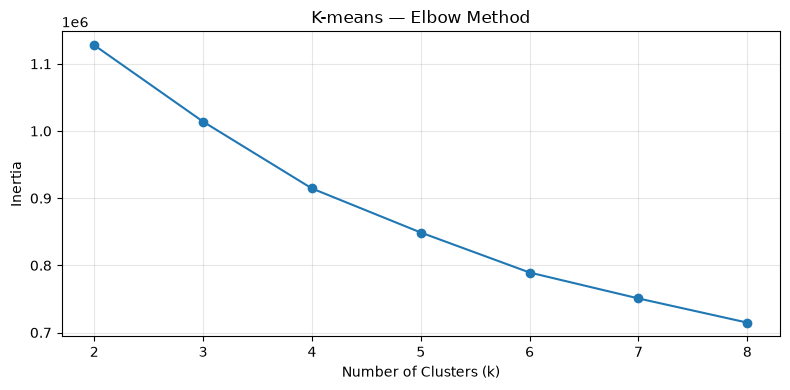

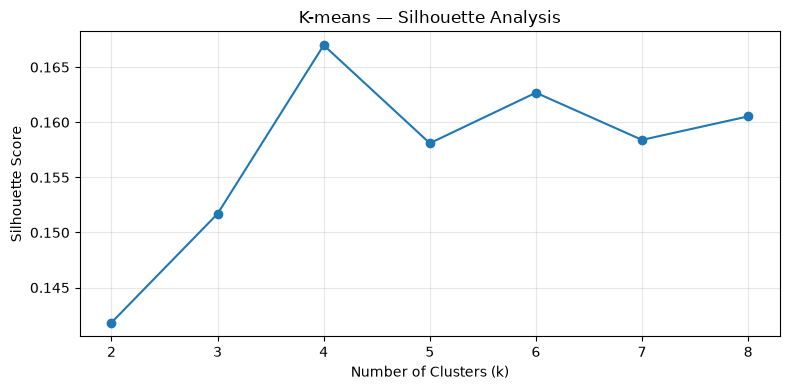

In [4]:
# Elbow Method
plt.figure(figsize=(8, 4))

plt.plot(
    k_results["k"],
    k_results["Inertia"],
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("K-means — Elbow Method")
plt.xticks(k_results["k"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Silhouette Score
plt.figure(figsize=(8, 4))

plt.plot(
    k_results["k"],
    k_results["Silhouette Score"],
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("K-means — Silhouette Analysis")
plt.xticks(k_results["k"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### B.2 — How to interpret the results
Use the calculated scores and elbow plot above to justify a choice of K. A low Silhouette Score means the resulting groups are not clearly separated. The remaining sections use **K=4 as a consistent exploratory baseline**; it is not claimed to be optimal.

### B.3 — Cluster Size Analysis

We apply K-means with k = 4 to the complete standardized dataset.

We examine the number and proportion of accounts assigned to each cluster to identify possible imbalances or very small clusters.

In [5]:
# K=4 illustrative baseline, consistent with the original notebook
X = X_candidates['all_features']
kmeans = KMeans(n_clusters=K_BASELINE, random_state=RANDOM_STATE, n_init=10)
cluster_labels = kmeans.fit_predict(X)
cluster_sizes = pd.Series(cluster_labels, name='Cluster').value_counts().sort_index()
cluster_summary = pd.DataFrame({
    'Accounts': cluster_sizes,
    'Percentage (%)': (cluster_sizes / len(X) * 100).round(2),
})
display(cluster_summary)
print('Total accounts:', int(cluster_sizes.sum()))

,Accounts,Percentage (%)
Cluster,,
0,32459,37.51
1,21931,25.35
2,11205,12.95
3,20930,24.19


Total accounts: 86525


#### B.3 — Cluster Size Results
Interpret the **computed** cluster-size table above. Check whether any cluster is very small or disproportionately large. Cluster numbers are arbitrary labels, not ranks.

### B.4 — Cluster Centroid Analysis

We examine the centroids of the four clusters to identify their main behavioral characteristics.

Since the features are standardized, positive centroid values indicate above-average characteristics, while negative values indicate below-average characteristics.

In [6]:
centroid_df = pd.DataFrame(
    kmeans.cluster_centers_, columns=features_all,
    index=[f'Cluster {i}' for i in range(K_BASELINE)]
)
display(centroid_df.T.round(2))

,Cluster 0,Cluster 1,Cluster 2,Cluster 3
post_count,-0.24,0.17,1.27,-0.48
ambiguous_post_count,-0.04,-0.02,-0.01,0.08
posting_intensity,0.06,0.46,-0.75,-0.18
follower_count,0.13,0.45,-0.25,-0.54
following_count,0.26,0.31,-0.14,-0.65
account_age_days,0.41,-0.07,-0.51,-0.29
activity_lifespan_days,-0.38,-0.39,2.39,-0.28
repost_ratio,0.98,-0.46,-0.14,-0.96
reply_ratio,-0.36,1.05,-0.14,-0.48
mention_ratio,0.82,0.10,-0.25,-1.24


#### B.4 — Cluster Centroid Results
Interpret centroids using the **actual table above**. Since the input is standardized, positive values generally indicate above-average behavior in that transformed feature, and negative values indicate below-average behavior. Cluster IDs and behavioral profiles can change after fixing input data.

### B.5 — Cluster Profiles in Original Units

We examine median feature values for each cluster using the original account-level data.

This allows us to interpret the clusters in meaningful units, such as the number of posts, activity lifespan in days, and interaction ratios.

In [7]:
# Original-unit profiles (for interpretation, not model fitting)
ORIGINAL_PATH = PROCESSED_DIR / 'df_account_features_eda.csv.gz'
if not ORIGINAL_PATH.is_file():
    print('Original-units file not found; skipping profiles:', ORIGINAL_PATH)
else:
    df_original = pd.read_csv(
        ORIGINAL_PATH, dtype={'ioCountry': 'string', 'accountid': 'string'}
    )
    cluster_assignments = account_ids.copy()
    cluster_assignments['Cluster'] = cluster_labels
    df_profiles = df_original.merge(
        cluster_assignments, on=account_keys, how='inner', validate='one_to_one'
    )
    profile_features = [c for c in [
        'post_count', 'posting_intensity', 'activity_lifespan_days',
        'repost_ratio', 'reply_ratio', 'mention_ratio',
        'hashtag_ratio', 'url_ratio', 'unique_languages'
    ] if c in df_profiles.columns]
    if profile_features:
        cluster_profiles = df_profiles.groupby('Cluster')[profile_features].median()
        display(cluster_profiles.T.round(2))
    else:
        print('No expected profile features found in the original dataset.')

Cluster,0,1,2,3
post_count,16.00,34.00,173.00,8.00
posting_intensity,15.00,33.00,1.19,6.00
activity_lifespan_days,0.00,0.00,169.00,0.00
repost_ratio,0.95,0.20,0.32,0.00
reply_ratio,0.00,0.27,0.02,0.00
mention_ratio,1.00,0.68,0.53,0.00
hashtag_ratio,0.52,0.27,0.45,0.99
url_ratio,0.74,0.21,0.43,0.95
unique_languages,1.00,2.00,3.00,1.00


### B.6 — Cluster Visualization

We visualize the standardized cluster centroids to better understand the behavioral characteristics of each cluster.

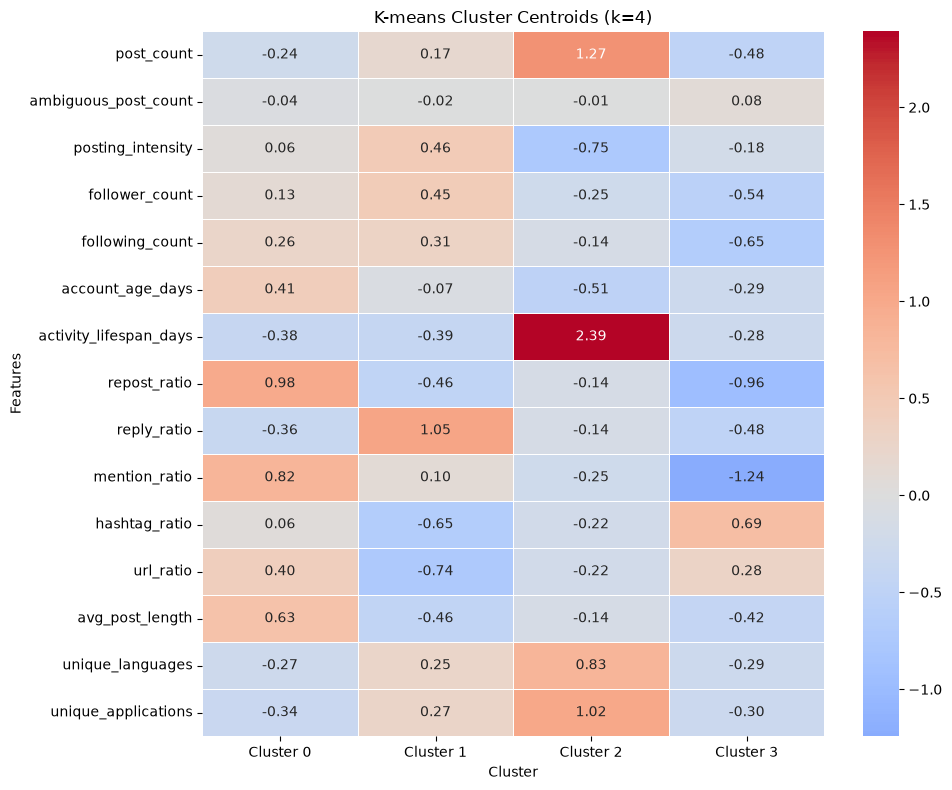

In [8]:
# Visualize the standardized cluster centroids
plt.figure(figsize=(10, 8))

sns.heatmap(
    centroid_df.T,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("K-means Cluster Centroids (k=4)")
plt.xlabel("Cluster")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

### B.7 — PCA Cluster Visualization

We use Principal Component Analysis (PCA) to project the 14-dimensional account features into two dimensions.

Each point represents an account, colored according to its K-means cluster.

This visualization helps us examine cluster separation and overlap. However, PCA is used only for visualization; clustering was performed using the original 14-dimensional feature space.

In [9]:
from sklearn.decomposition import PCA

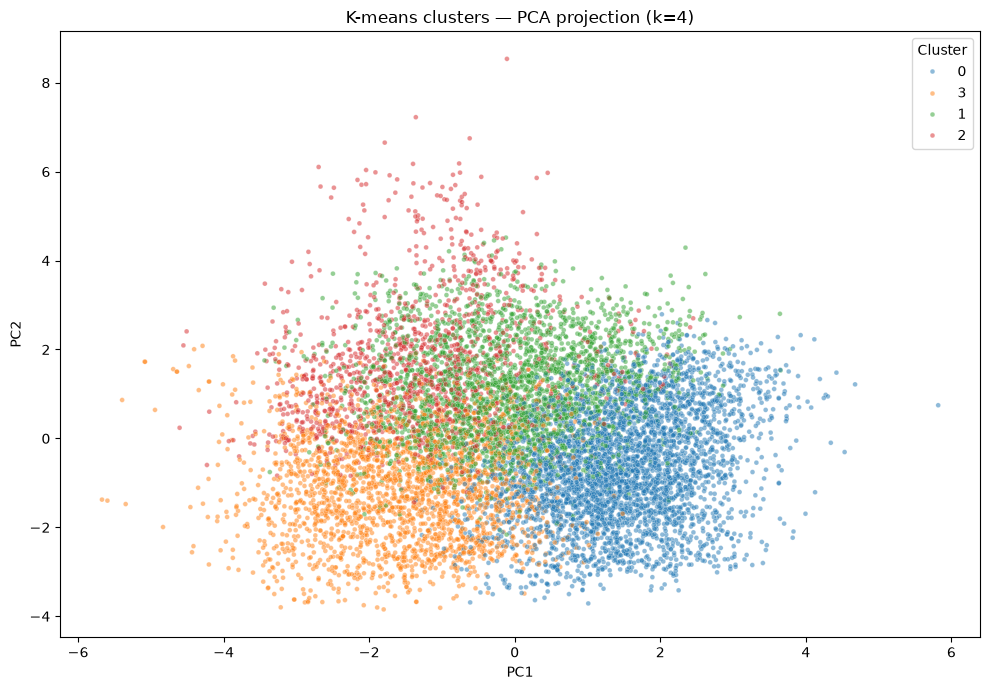

Variance explained by first two PCs: 36.14%


In [10]:
X = X_candidates['all_features']
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
rng = np.random.default_rng(RANDOM_STATE)
pca_sample = rng.choice(len(X), size=min(10000, len(X)), replace=False)
df_pca = pd.DataFrame({
    'PC1': X_pca[pca_sample, 0],
    'PC2': X_pca[pca_sample, 1],
    'Cluster': cluster_labels[pca_sample].astype(str)
})
plt.figure(figsize=(10, 7))
sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='Cluster',
                palette='tab10', s=12, alpha=0.5)
plt.title(f'K-means clusters — PCA projection (k={K_BASELINE})')
plt.tight_layout()
plt.show()
print('Variance explained by first two PCs:',
      f'{pca.explained_variance_ratio_.sum() * 100:.2f}%')

#### B.7 — PCA Visualization Results
Use the printed proportion of variance explained by PC1 and PC2 to judge how much of the feature variation appears in this two-dimensional view. Overlap in PCA is **not** definitive proof of overlapping clusters in the original feature space.

### B.8 — Feature Configuration Comparison

We compare K-means clustering using four feature configurations:

- All 14 numerical features.
- Without posting intensity.
- Without posting intensity and post count.
- Without mention ratio.

We initially keep k = 4 to examine how feature selection affects clustering quality, using the same evaluation sample for all configurations.

In [11]:
# Compare alternative feature sets at the same K, evaluation sample, and seed
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(len(df_clustering), size=min(2000, len(df_clustering)), replace=False)
comparison_results = []
for name, X in X_candidates.items():
    model = KMeans(n_clusters=K_BASELINE, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X)
    sample_labels = labels[sample_idx]
    score = (silhouette_score(X[sample_idx], sample_labels)
             if len(np.unique(sample_labels)) > 1 else np.nan)
    comparison_results.append({
        'Configuration': name, 'Features': X.shape[1], 'Silhouette Score': score
    })
comparison_df = pd.DataFrame(comparison_results)
display(comparison_df.sort_values('Silhouette Score', ascending=False).round(4))

,Configuration,Features,Silhouette Score
2,no_activity,13,0.1887
1,no_intensity,14,0.1762
0,all_features,15,0.1670
3,no_mention,14,0.1498


### B.9 — K-means Evaluation Without Activity Features
We repeat the K sweep on the feature set excluding `post_count` and `posting_intensity`. Compare its scores against the full-feature baseline using the actual outputs.

In [12]:
X_no_activity = X_candidates['no_activity']
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(len(X_no_activity), size=min(2000, len(X_no_activity)), replace=False)
results_no_activity = []
for k in K_VALUES:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_no_activity)
    sample_labels = labels[sample_idx]
    score = (silhouette_score(X_no_activity[sample_idx], sample_labels)
             if len(np.unique(sample_labels)) > 1 else np.nan)
    results_no_activity.append({'k': k, 'Inertia': model.inertia_, 'Silhouette Score': score})
k_results_no_activity = pd.DataFrame(results_no_activity)
display(k_results_no_activity.round(4))

,k,Inertia,Silhouette Score
0,2,957558.9375,0.1601
1,3,852691.1875,0.1739
2,4,772578.0000,0.1887
3,5,713329.0000,0.1930
4,6,666999.7500,0.1527
5,7,623683.5000,0.1586
6,8,592260.2500,0.1555


#### B.9 — Results
Examine the calculated Silhouette Scores for the reduced feature set. Choose K based on these results, not on an earlier notebook execution.

### B.10 — Comparing Clustering Configurations

We compare the original 14-feature clustering solution with the 12-feature configuration.

We examine cluster sizes and calculate the Adjusted Rand Index (ARI) to understand how removing posting activity features affects cluster assignments.

In [13]:
kmeans_no_activity = KMeans(n_clusters=K_BASELINE, random_state=RANDOM_STATE, n_init=10)
labels_no_activity = kmeans_no_activity.fit_predict(X_candidates['no_activity'])
sizes_no_activity = pd.Series(labels_no_activity, name='Cluster').value_counts().sort_index()
summary_no_activity = pd.DataFrame({
    'Accounts': sizes_no_activity,
    'Percentage (%)': (sizes_no_activity / len(labels_no_activity) * 100).round(2),
})
display(summary_no_activity)
ari = adjusted_rand_score(cluster_labels, labels_no_activity)
print(f'ARI between full and no_activity solutions: {ari:.3f}')

,Accounts,Percentage (%)
Cluster,,
0,20561,23.76
1,33800,39.06
2,10760,12.44
3,21404,24.74


ARI between full and no_activity solutions: 0.838


#### B.10 — Configuration Comparison Results
Compare the observed Silhouette Scores from B.8 and the Adjusted Rand Index (ARI) printed here. ARI near 1 means similar assignments; ARI near 0 means little agreement beyond chance. Differences in cluster-number labels alone do not affect ARI.

### B.11 — Interpretation of the 12-Feature Clusters

We examine the standardized centroids of the 12-feature configuration to identify the behavioral characteristics of its four clusters.

This allows us to compare their interpretation with the original 14-feature solution before selecting a final configuration.

In [14]:
centroids_no_activity = pd.DataFrame(
    kmeans_no_activity.cluster_centers_,
    columns=candidate_feature_sets['no_activity'],
    index=[f'Cluster {i}' for i in range(K_BASELINE)],
)
display(centroids_no_activity.T.round(2))

,Cluster 0,Cluster 1,Cluster 2,Cluster 3
ambiguous_post_count,0.10,-0.03,-0.03,-0.03
follower_count,-0.49,0.18,-0.30,0.34
following_count,-0.64,0.29,-0.15,0.23
account_age_days,-0.28,0.40,-0.53,-0.09
activity_lifespan_days,-0.25,-0.37,2.40,-0.38
repost_ratio,-0.99,0.96,-0.12,-0.50
reply_ratio,-0.51,-0.36,-0.14,1.13
mention_ratio,-1.30,0.80,-0.22,0.09
hashtag_ratio,0.76,0.06,-0.27,-0.69
url_ratio,0.35,0.39,-0.27,-0.82


#### B.11 — Results
Use the centroid values above to characterize the reduced-feature clusters. Do not reuse earlier cluster descriptions unless the rerun supports them.

### B.12 — IO vs. Control Cluster Composition

We compare the four clusters obtained using the 12-feature configuration with the original IO/control labels.

The labels were excluded during clustering and are used only for external evaluation.

We examine the number and proportion of IO and control accounts in each cluster.

In [15]:
# Evaluate IO/control composition only after clustering (never as model features)
LABELS_PATH = PROCESSED_DIR / 'df_account_labels.csv.gz'
if not LABELS_PATH.is_file():
    print('Optional labels file unavailable; skipping IO/control composition.')
else:
    df_labels_eval = pd.read_csv(
        LABELS_PATH,
        dtype={'ioCountry': 'string', 'accountid': 'string', 'is_control': 'string'}
    )
    df_eval = account_ids.copy()
    df_eval['Cluster'] = labels_no_activity
    df_eval = df_eval.merge(df_labels_eval, on=account_keys, how='left', validate='one_to_one')
    df_eval['account_group'] = (df_eval['is_control'].str.strip().str.lower()
                                .map({'true': 'Control', 'false': 'IO'}))
    composition = pd.crosstab(df_eval['Cluster'], df_eval['account_group'])
    percent = composition.div(composition.sum(axis=1), axis=0).mul(100).round(2)
    print('Accounts without valid labels:', int(df_eval['account_group'].isna().sum()))
    display(composition)
    display(percent)

# Save model assignments, with account IDs, for downstream analyses.
assignments = account_ids.copy()
assignments['cluster_all_14_k4'] = cluster_labels
assignments['cluster_no_activity_k4'] = labels_no_activity
assignment_file = OUTPUT_DIR / 'account_cluster_assignments.csv.gz'
assignments.to_csv(assignment_file, index=False, compression='gzip')
k_results.to_csv(OUTPUT_DIR / 'kmeans_all_features_k_sweep.csv', index=False)
k_results_no_activity.to_csv(OUTPUT_DIR / 'kmeans_no_activity_k_sweep.csv', index=False)
comparison_df.to_csv(OUTPUT_DIR / 'feature_configuration_comparison.csv', index=False)
print('Saved cluster assignments:', assignment_file)

Accounts without valid labels: 1


account_group,Control,IO
Cluster,,
0,19209,1352
1,33423,377
2,2017,8742
3,20959,445


account_group,Control,IO
Cluster,,
0,93.42,6.58
1,98.88,1.12
2,18.75,81.25
3,97.92,2.08


Saved cluster assignments: /Users/ramy/Courses/Data Mining /project/Data-Mining-Project-/data/clustering_results/account_cluster_assignments.csv.gz
